You are a quantitative risk analyst evaluating the systematic risk profile of Apple Inc. relative to the broader market index. Your goal is to map the linear relationship between market movements and asset performance using the provided large-scale interval returns dataset.

Your Task

Using the generated CSV file, execute a simple linear regression analysis to answer the following without reviewing pre-calculated outcomes:
1. Define the Model:
 Explicitly identify which variable acts as the predictor (independent variable \(X\)) and which acts as the response (dependent variable Y).
2. Calculate Key Coefficients: Find the exact numerical values for the ordinary least squares (OLS) slope coefficient (\(\beta \)) and the intercept (\(\alpha \)).
3. Assess Model Fit: Compute the Coefficient of Determination (\(R^{2}\)) to evaluate what percentage of the variance in Apple's returns is explained by the market index.
4. Financial Interpretation: Based on your calculated metrics, determine whether Apple behaves as an aggressive (\(\beta > 1\)) or defensive (\(\beta < 1\)) asset during these intervals, and assess if it generated any abnormal risk-adjusted return (\(\alpha \neq 0\)).

H0: Model is Not Useful 

H1 : Model is Useful 

TOOL : LINEAR REGRESSION 

1. Define the Model: Explicitly identify which variable acts as the predictor (independent variable \(X\)) and which acts as the response (dependent variable \(Y\)).

Independednt Variable (X): Asset Performance

Dependednt Variable (Y): Market Movement 

In [2]:
import numpy as np 
import pandas as pd
from sklearn.model_selection import train_test_split
import statsmodels.stats as sm


from statsmodels.formula.api import ols

In [3]:
df=pd.read_csv("finance_regression_data.csv")

In [4]:
df.head()

,Row_ID,SPY_Return,AAPL_Return
0,1,0.001093,0.002166
1,2,-0.000177,-0.000812
2,3,0.001395,0.002165
3,4,0.003146,0.001800
4,5,-0.000368,0.003001


In [5]:
X=df['SPY_Return']
Y=df['AAPL_Return']

In [6]:
import statsmodels.api as sm
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.20)
x_train_const=sm.add_constant(x_train,prepend=False)

model=sm.OLS(y_train,x_train_const).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            AAPL_Return   R-squared:                       0.735
Model:                            OLS   Adj. R-squared:                  0.735
Method:                 Least Squares   F-statistic:                 1.222e+05
Date:                Fri, 16 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:44:59   Log-Likelihood:             2.2371e+05
No. Observations:               44000   AIC:                        -4.474e+05
Df Residuals:                   43998   BIC:                        -4.474e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
SPY_Return     1.2492      0.004    349.635      0.0

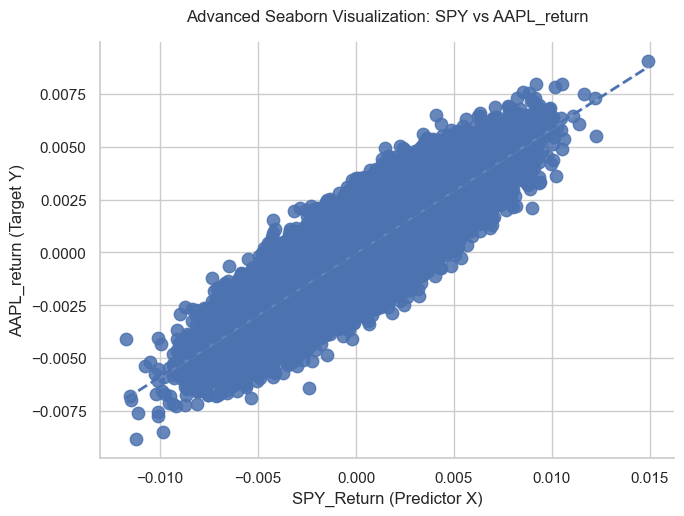

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 2. Set clean statistical plotting style
sns.set_theme(style="whitegrid")

# 3. Create the regression plot with category color-coding (hue)
g = sns.lmplot(
    data=df,
    x="AAPL_Return",
    y="SPY_Return",           # Colors dots by placement status (0 or 1)
    palette="Set1",         # Clear categorical distinct color mapping
    height=5,
    aspect=1.4,
    scatter_kws={"s": 80, "alpha": 0.85},
    line_kws={"linewidth": 2, "linestyle": "--"} 
)

# 4. Refine layout details via Matplotlib adjustments
g.set_axis_labels("SPY_Return (Predictor X)", "AAPL_return (Target Y)")
plt.title("Advanced Seaborn Visualization: SPY vs AAPL_return", fontsize=12, pad=15)

plt.show()

P_value <0.05 :Therefore We Reject the Null Hypothesis

F_Stats<0.05 : Therefore We Reject the Null Hypothesis 

Result : Model is Useful 

R^2 : 0.73  

Model can explain 73% variance in AAPL_return rate 

Y=1.2510(X)+C


Scenario A: Using the 1-Year (YoY) SPY Return

Input (X): 17.47 (representing the +17.47% SPY return)

Expected Output :21.84


In [ ]:
Y=1.21510*(17.47) + 0
Y

21.227797

Conclusion : For instance, a strong 17.47% YoY market gain is magnified into an expected 21.84% return for the asset.